In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

import kagglehub

/kaggle/input/datasets/mohammadtalib786/retail-sales-dataset/retail_sales_dataset.csv


In [2]:
#load dataset
df = pd.read_csv('/kaggle/input/datasets/mohammadtalib786/retail-sales-dataset/retail_sales_dataset.csv')

In [3]:
#first 5 rows and last 5 rows
pd.concat([df.head(), df.tail()])

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100
995,996,2023-05-16,CUST996,Male,62,Clothing,1,50,50
996,997,2023-11-17,CUST997,Male,52,Beauty,3,30,90
997,998,2023-10-29,CUST998,Female,23,Beauty,4,25,100
998,999,2023-12-05,CUST999,Female,36,Electronics,3,50,150
999,1000,2023-04-12,CUST1000,Male,47,Electronics,4,30,120


In [4]:
#change column names to lowercase and replace spaces with '_'
df.columns = df.columns.str.lower().str.replace(' ', '_')

In [5]:
#information about dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   transaction_id    1000 non-null   int64 
 1   date              1000 non-null   object
 2   customer_id       1000 non-null   object
 3   gender            1000 non-null   object
 4   age               1000 non-null   int64 
 5   product_category  1000 non-null   object
 6   quantity          1000 non-null   int64 
 7   price_per_unit    1000 non-null   int64 
 8   total_amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


In [6]:
#change datatypes of date, gender, and product category
df['date'] = pd.to_datetime(df['date'])
df['gender'] = df['gender'].astype('category')
df['product_category'] = df['product_category'].astype('category')
df.dtypes

transaction_id               int64
date                datetime64[ns]
customer_id                 object
gender                    category
age                          int64
product_category          category
quantity                     int64
price_per_unit               int64
total_amount                 int64
dtype: object

In [7]:
#remove transaction id and customer id columns
df.drop(columns=['transaction_id', 'customer_id'])

,date,gender,age,product_category,quantity,price_per_unit,total_amount
0,2023-11-24,Male,34,Beauty,3,50,150
1,2023-02-27,Female,26,Clothing,2,500,1000
2,2023-01-13,Male,50,Electronics,1,30,30
3,2023-05-21,Male,37,Clothing,1,500,500
4,2023-05-06,Male,30,Beauty,2,50,100
...,...,...,...,...,...,...,...
995,2023-05-16,Male,62,Clothing,1,50,50
996,2023-11-17,Male,52,Beauty,3,30,90
997,2023-10-29,Female,23,Beauty,4,25,100
998,2023-12-05,Female,36,Electronics,3,50,150


In [8]:
#summary statistics
df.describe()

,transaction_id,date,age,quantity,price_per_unit,total_amount
count,1000.000000,1000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,2023-07-03 00:25:55.200000256,41.39200,2.514000,179.890000,456.000000
min,1.000000,2023-01-01 00:00:00,18.00000,1.000000,25.000000,25.000000
25%,250.750000,2023-04-08 00:00:00,29.00000,1.000000,30.000000,60.000000
50%,500.500000,2023-06-29 12:00:00,42.00000,3.000000,50.000000,135.000000
75%,750.250000,2023-10-04 00:00:00,53.00000,4.000000,300.000000,900.000000
max,1000.000000,2024-01-01 00:00:00,64.00000,4.000000,500.000000,2000.000000
std,288.819436,NaN,13.68143,1.132734,189.681356,559.997632


In [9]:
#check for duplicate rows
df.duplicated().sum()

np.int64(0)

# Univariate Analysis

## Gender

About an even split between gender

In [10]:
df['gender'].value_counts()

gender
Female    510
Male      490
Name: count, dtype: int64

<Axes: ylabel='count'>

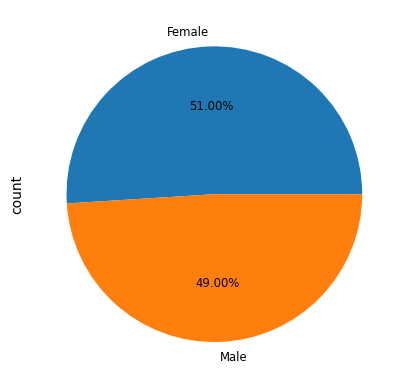

In [11]:
#pie chart of gender counts
df['gender'].value_counts().plot(kind='pie', autopct='%.2f%%', textprops={'size': 'small'})

## Product Category

About one third of purchases made in each category

In [12]:
df['product_category'].value_counts()

product_category
Clothing       351
Electronics    342
Beauty         307
Name: count, dtype: int64

<Axes: ylabel='count'>

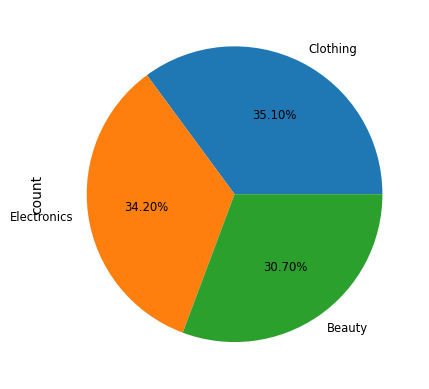

In [13]:
#pie chart of product category counts
df['product_category'].value_counts().plot(kind='pie', autopct='%.2f%%', textprops={'size': 'small'})

## Age

Data has a trimodal distrubtion of age. The youngest age (18), the eldest age (64), and about the midway point between these ages (42) are the most represented within the data.

<Axes: ylabel='Frequency'>

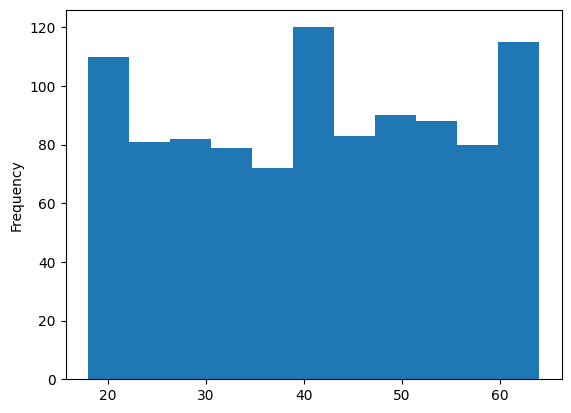

In [14]:
#histogram of age with 4-year intervals
df['age'].plot(kind='hist', bins=11, linewidth=0.5)

<Axes: ylabel='Frequency'>

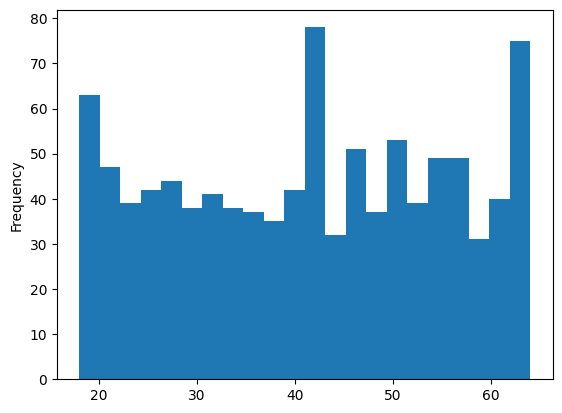

In [15]:
#histogram of age with 2 year intervals
df['age'].plot(kind='hist', bins=22, linewidth=0.5)

<Axes: ylabel='Frequency'>

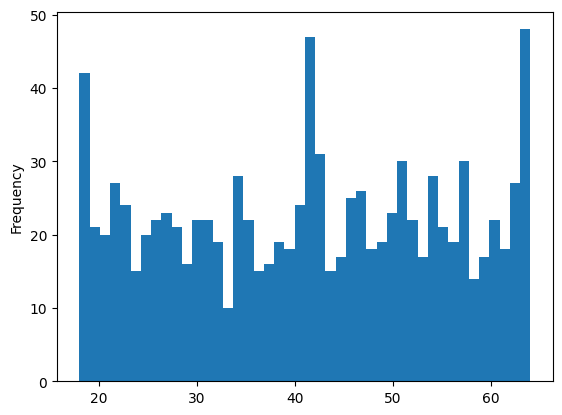

In [16]:
#histogram of age with 1 year interval
df['age'].plot(kind='hist', bins=44, linewidth=0.5)

## Quantity

Customers purchased one, two, three, or four products each about 25% of the time.

In [17]:
df['quantity'].value_counts()

quantity
4    263
1    253
2    243
3    241
Name: count, dtype: int64

<Axes: ylabel='count'>

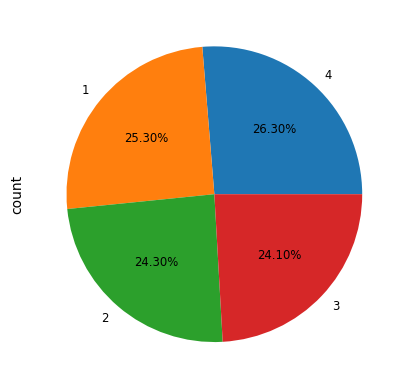

In [18]:
df['quantity'].value_counts().plot(kind='pie', autopct='%.2f%%', textprops={'size': 'small'})

## Total Amount Spent

Most customers spent less than $250 per transaction.

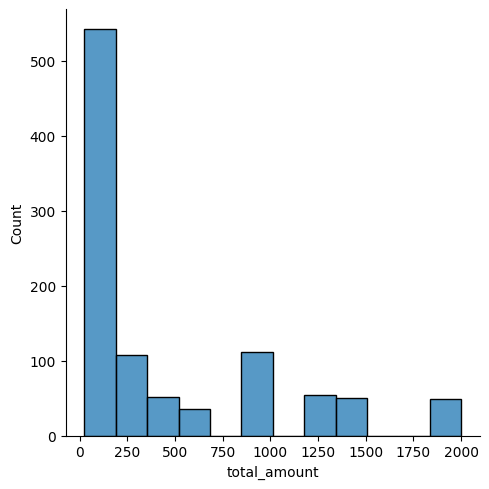

In [19]:
#histogram of total amount spent
sns.displot(df, x='total_amount')

# Bivariate Analysis

## Age and Product Category

The distribution of customers' ages is similar across product categories. The distribution of customers' ages purchasing beauty products is slighly younger than both the distribution of customers' ages purchasing clothing and electronics. 

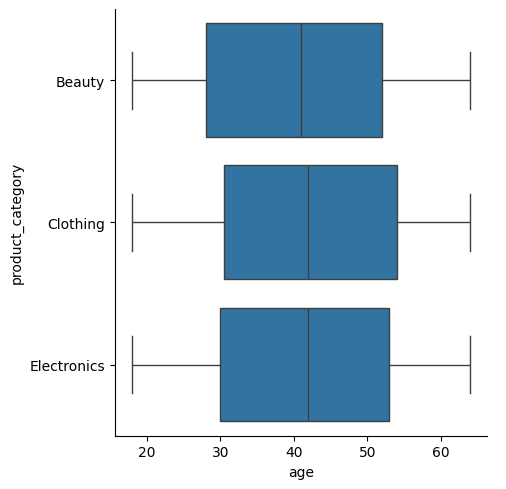

In [20]:
#boxplot of age and product category
sns.catplot(df, x='age', y='product_category', kind='box')

The mean age of customers is similar across product categories, about 40 years old. The mean age of customers purchasing clothing products is the highest of the three at about 41.9 years old.

[Text(0, 0, '40.3713'), Text(0, 0, '41.9487'), Text(0, 0, '41.7368')]

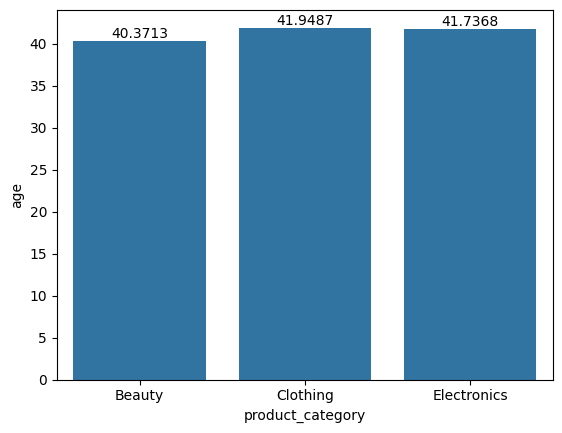

In [21]:
#barplot of average age of customer based on product category
ax = sns.barplot(df, y='age', x='product_category', errorbar=None)
ax.bar_label(ax.containers[0], fontsize=10)

In [22]:
#determining average age of customers depending on product category bought
df[['age', 'product_category']].groupby(['product_category'], observed=True).mean()

,age
product_category,
Beauty,40.371336
Clothing,41.948718
Electronics,41.736842


## Age and Total Amount Spent

The distribution of amount of money spent is split into four distinct bands. For all ages, the highest concentration of amount of money spent is less than $250.  

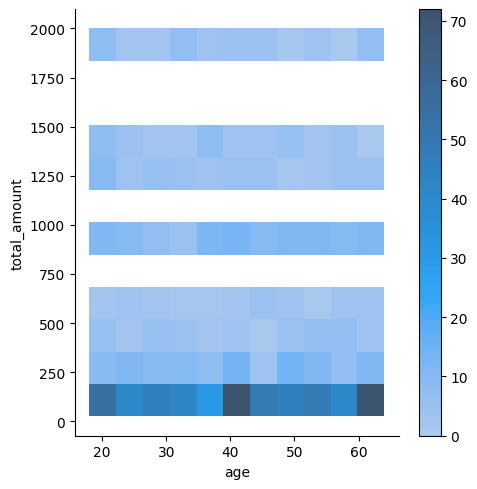

In [23]:
#distribution of total amount spent depending on customer's age
sns.displot(df, x='age', y='total_amount', cbar=True)

Customers aged 37 spent the largest average amount of money, \\$728.12. Customers aged 39 spent the lowest average amount of money, \\$255.28. For comparison, the average amount of money spent is \\$456.00. Customers aged 37 spent, on average, about %59.7 more than the average amount of money spent for all customers. Customers aged 39 spent, on average, about %44 less than the average amount of money spent for all customers.

<Axes: xlabel='age'>

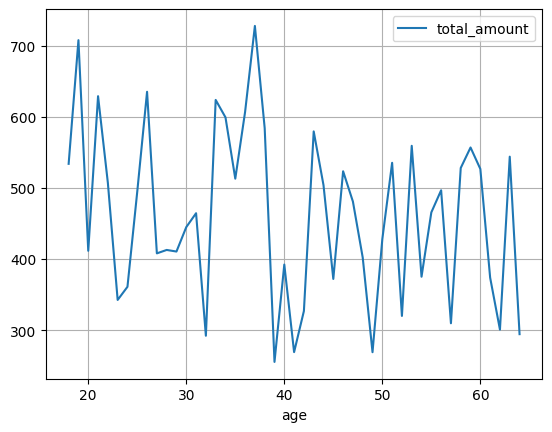

In [24]:
#average amount of money a customer spends depending on their age
avg_spent_by_age = df[['age', 'total_amount']].groupby(['age'], observed=True).mean()
avg_spent_by_age.plot(grid=True)

In [25]:
#max value of the average amount of money spent depending on age
avg_spent_by_age.max()

total_amount    728.125
dtype: float64

In [26]:
#the age group that has the highest average amount of money spent
avg_spent_by_age.idxmax()

total_amount    37
dtype: int64

In [27]:
#the lowest average amount of money spent based on age
avg_spent_by_age.min()

total_amount    255.277778
dtype: float64

In [28]:
#finding the age with the lowest average amount of money spent
avg_spent_by_age.idxmin()

total_amount    39
dtype: int64

<Axes: xlabel='age'>

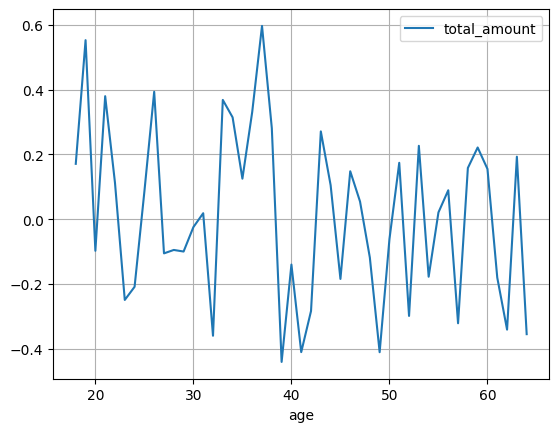

In [29]:
#difference as a percentage between average amount of money spent depending on age and average amount of money spent for all customers
avg_spent_by_age.apply(lambda x : (x - 456) / 456).plot(grid = True)

## Age and Quantity

The distribution of customers' ages purchasing 1 product or 4 products seems to be bimodal with peaks around slighly older than 40 and slighly younger than 64. The distribution of customers' ages purchasing 2 products seems to increase toward customers older than 40. The distribution of customers' ages purchasing 3 products is flatter than the other 3 distributions with no noticable peaks. 

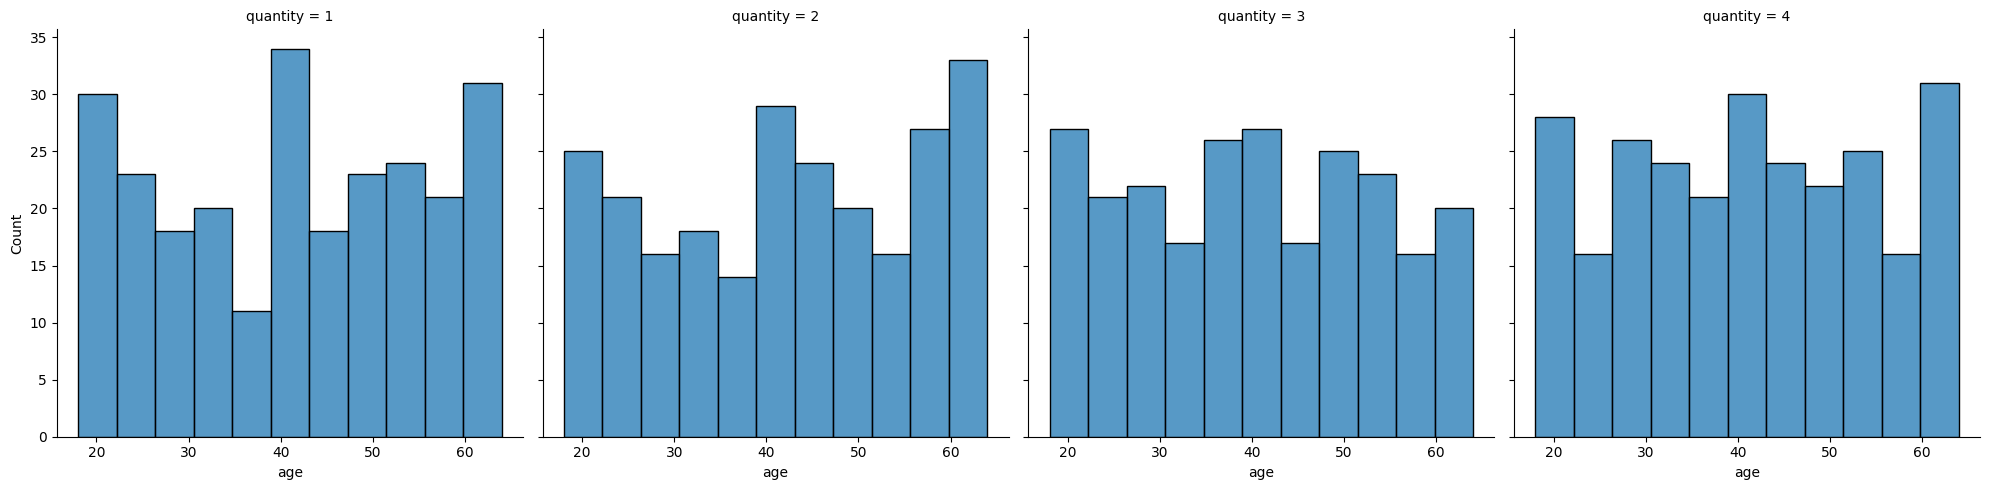

In [30]:
#histogram of age and quantity of products purchased
sns.displot(df, x='age', col='quantity')

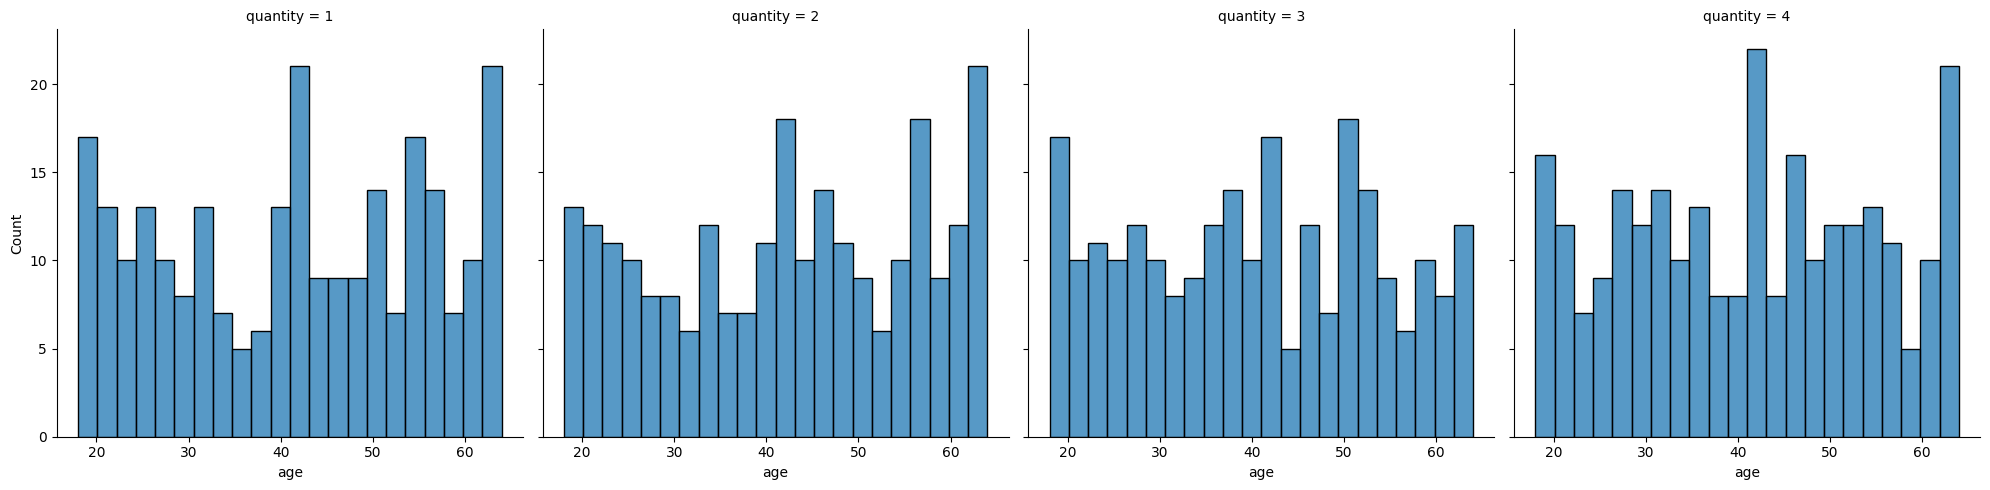

In [31]:
#histogram with bars at 2-year intervals
sns.displot(df, x='age', bins=22, col='quantity')

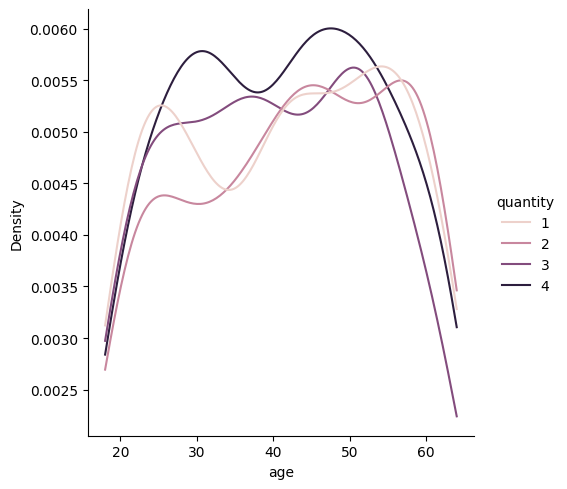

In [32]:
#kde of quantity of products purchased based on age
sns.displot(df, x='age', hue='quantity', kind='kde', cut=0)

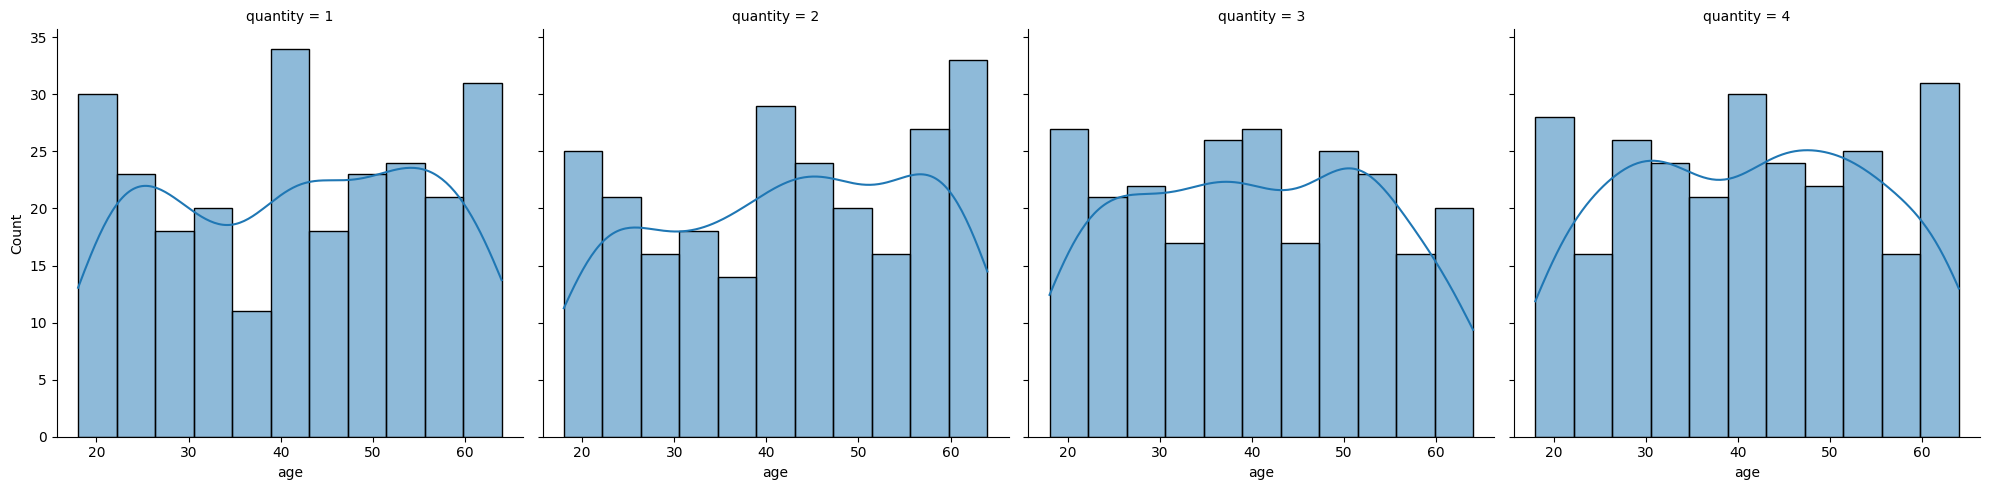

In [33]:
#histogram with kde
sns.displot(df, x='age', col='quantity', kde=True)

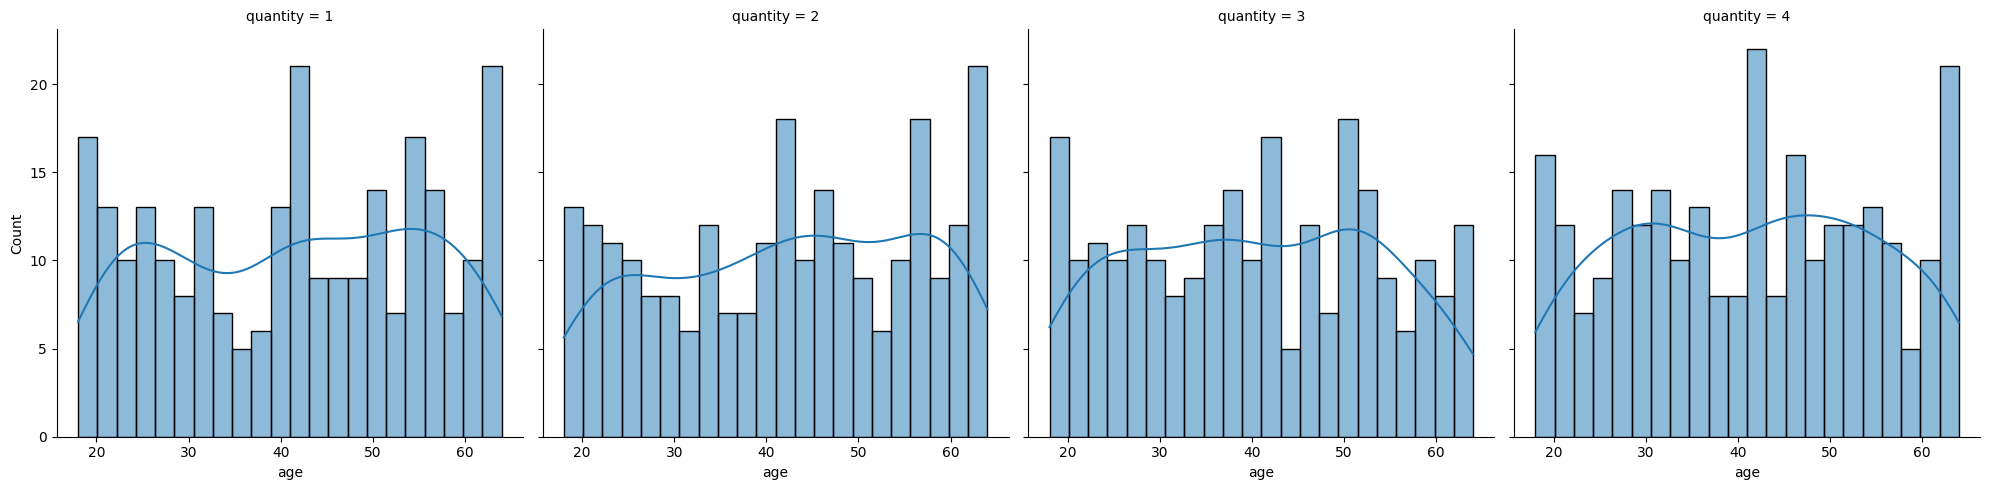

In [34]:
#histogram with kde with bars at 2-year intervals
sns.displot(df, x='age', bins=22, col='quantity', kde=True)

## Product Category and Total Amount Spent

The distribution of total amount of money spent on beauty products and the distribution of total amount of money spent on electronics is similar. They share similar medians and interquartile ranges. The total amount of money spent on clothing has a similar median to that of beauty products and electronics. However, the 75th percentile of the total amount of money spent on clothing is much lower thant that of beauty products and electronics. This indicates a distribution of smaller amounts of money spent on clothing products than on beauty products or electronics. The average amount of money spent is similar across product categories, about \\$450.

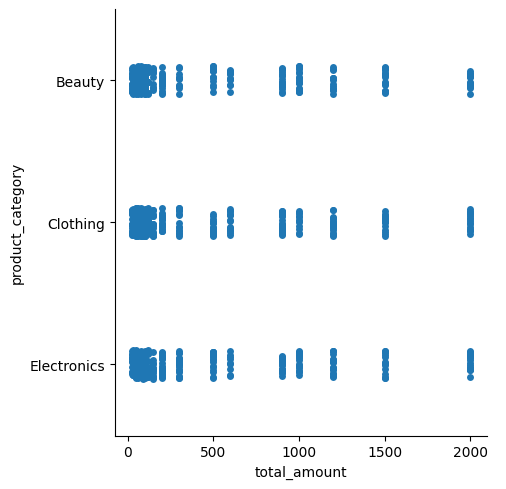

In [35]:
#scatterplot of total amount spent and product category
sns.catplot(df, x='total_amount', y='product_category')

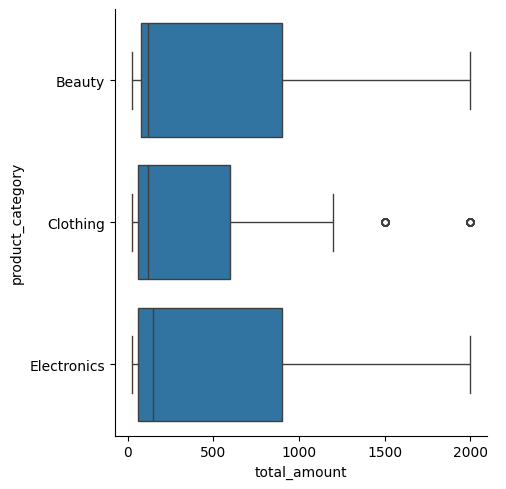

In [36]:
#boxplot of total amount spent and product category
sns.catplot(df, x='total_amount', y='product_category', kind='box')

[Text(0, 0, '$467.48'), Text(0, 0, '$443.25'), Text(0, 0, '$458.79')]

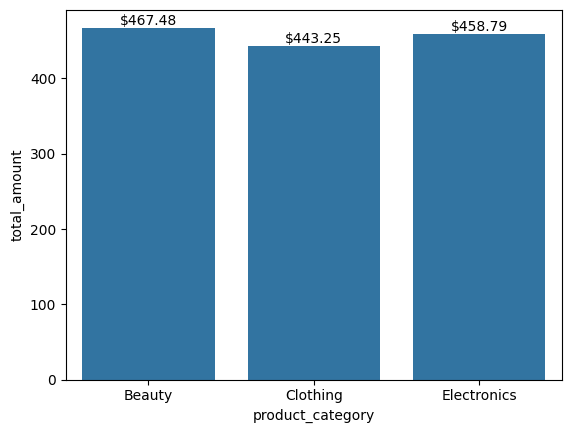

In [37]:
#bar plot showing the average amount of money spent depending on product category
ax = sns.barplot(df, x='product_category', y='total_amount', errorbar=None)
ax.bar_label(ax.containers[0], fontsize=10, fmt='$%.2f')

# Multivariate Analysis

## Age, Total Amount Spent, Gender

The distribution of total amount of money spent depending on the customer's age is similar when taking into account the customer's gender. The highest concentration of amount of money spent for both genders is less than \\$250. For both genders, customers aged around 20 years old, 40 years old, and 60 years old have the highest concentration of amount of money spent less than \\$250. This concentration is likely due to the fact that there are more customers of ages around 20 years old, 40 years old, and 60 years old within the data (see univariate analysis: age) and that most customers regardless of age and gender spent less than \\$250.

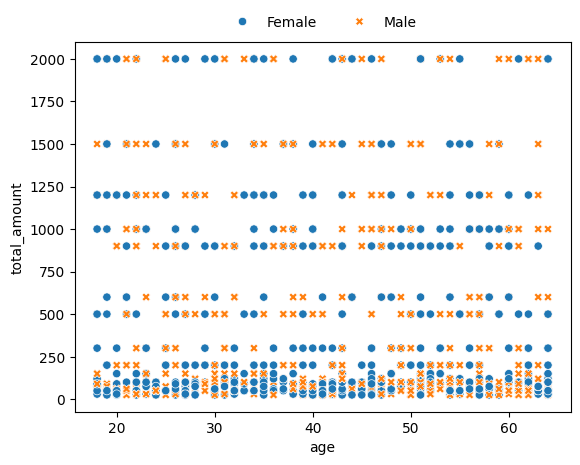

In [38]:
#scatterplot of total amount spent based on age and gender
sns.scatterplot(df, x='age', y='total_amount', hue='gender', style='gender')
plt.legend(
    bbox_to_anchor=(0.5, 1.02),
    loc="lower center",
    borderaxespad=0,
    frameon=False,
    ncol=3,
)

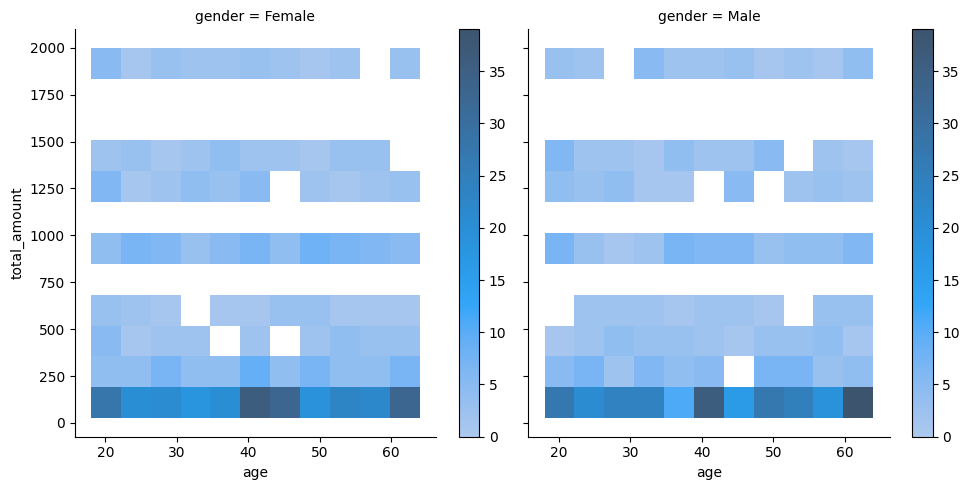

In [39]:
#bivariate histogram of total amount spent based on age and gender
sns.displot(df, x='age', y='total_amount', col='gender', cbar=True)

The highest average amount of money spent by female customers was \\$860.71, spent by customers aged 34 years old. The highest average amount of money spent by male customers was \\$1050.00, spent by customers aged 33 years old. The lowest average amount of money spent by female customers was \\$65.00, spent by customers aged 45 years old. The lowest average amount of money spent by male customers was \\$137.78, spent by customers aged 39 years old.

For comparison the average amount of money spent by female customers is \\$456.55. For male customers the average amount of money spent is \\$455.43. Male customers aged 33 years old spent on average %130.6 more than the average amount of money spent by all male customers. Male customers aged 39 years old spent on average %69.7 less than the average. Female customers aged 34 years old spent on average %88.5 more than the average amount of money spent by all female customers. Female customers aged 45 years old spent on average %85.8 less than the average. 

In [40]:
#average amount of money spent based on age and gender
avg_money_spent_by_age_gender = df[['age', 'total_amount', 'gender']].groupby(['age', 'gender'], observed=True).mean()

In [41]:
#highest average amount of money spent based on gender
avg_money_spent_by_age_gender.groupby(level=1, observed=True).max()

,total_amount
gender,
Female,860.714286
Male,1050.000000


In [42]:
#finding age of highest average amount of money spent based on gender
avg_money_spent_by_age_gender.groupby(level=1, observed=True).idxmax()

,total_amount
gender,
Female,"(34, Female)"
Male,"(33, Male)"


In [43]:
#lowest average amount of money spent based on gender
avg_money_spent_by_age_gender.groupby(level=1, observed=True).min()

,total_amount
gender,
Female,65.000000
Male,137.777778


In [44]:
#finding age of lowest average amount of money spent based on gender
avg_money_spent_by_age_gender.groupby(level=1, observed=True).idxmin()

,total_amount
gender,
Female,"(45, Female)"
Male,"(39, Male)"


In [45]:
#finding average amount of money spent depending on their gender
avg_spent_by_gender = df[['gender', 'total_amount']].groupby(['gender'], observed=True).mean()
avg_spent_by_gender.head()

,total_amount
gender,
Female,456.549020
Male,455.428571


## Age, Total Amount Spent, Gender, Product Category

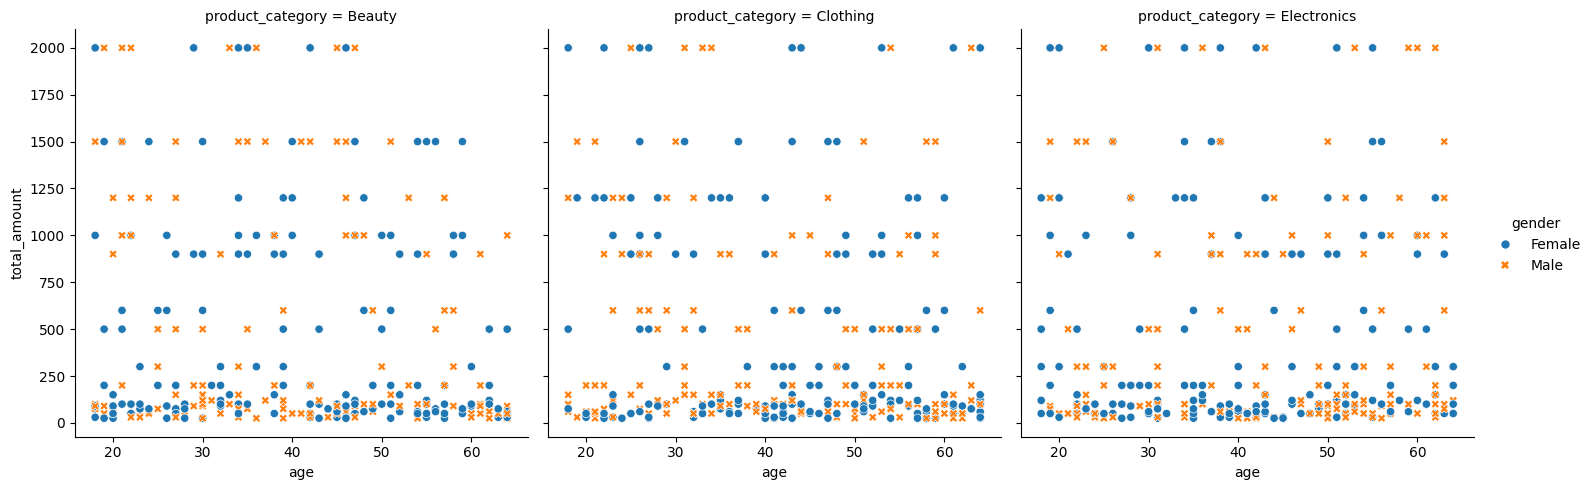

In [46]:
#scatterplots of total amount spent based on age, gender, and product category
sns.relplot(df, x='age', y='total_amount', hue='gender', style='gender', col='product_category', kind='scatter')

## Age, Product Category, Gender

The distribution of ages of customers buying beauty products is roughly the same between male and female customers. The median age of a female customer buying beauty products is slightly older than that of a male customer buying beauty products.

The distrubtion of ages of customers buying clothing is slightly older for female customers than male customers. 

The inverse is true for customers buying electronics. The distribution of ages of customers is slighly older for male customers than female customers. 

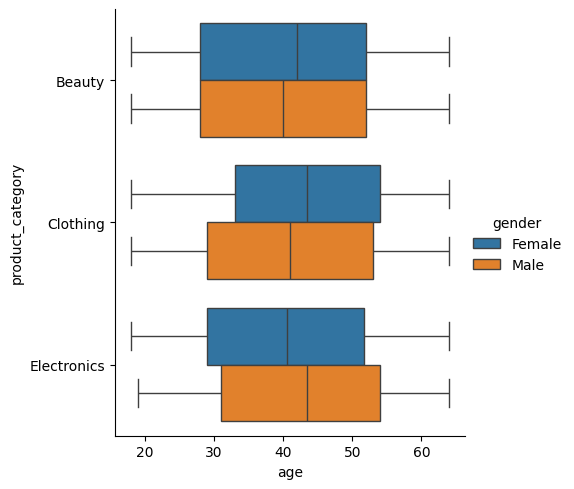

In [47]:
#box plot of product category and age and split by gender
sns.catplot(data=df, x = 'age', y='product_category', hue='gender', kind='box')

## Total Amount Spent, Product Category, Gender

The interquartile range of the amount of money a male or female customer spends on beauty products is roughly the same. Female customers have a higher median amount of money spent on beauty products than male customers. The interquartile range of the amount of money a male or female customer spends on electronics is roughly the same. Female customers have a slightly higher median amount of money spent on electronics than male customers. Female customers have a much higher interquartile range of the amount of money spent on clothing than male customers. The median amount of money spent on clothing is slighly less for female customers than male customers. This indicates female customers have a higher variance on the amount of money than spend on clothing than male customers.

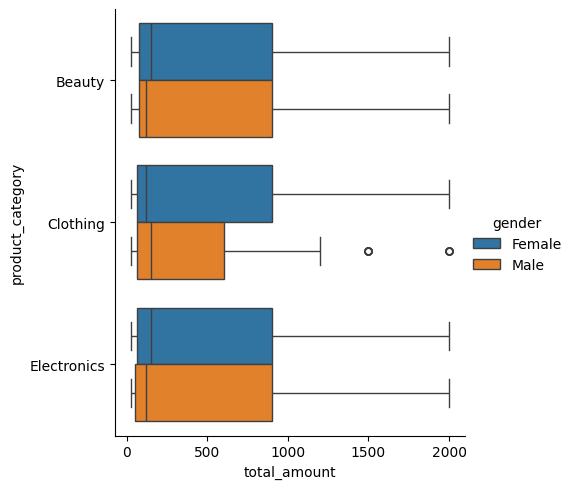

In [48]:
#boxplot of the quantity of items purchased based on product category and gender
sns.catplot(df, x='total_amount', y='product_category', hue='gender', kind='box')

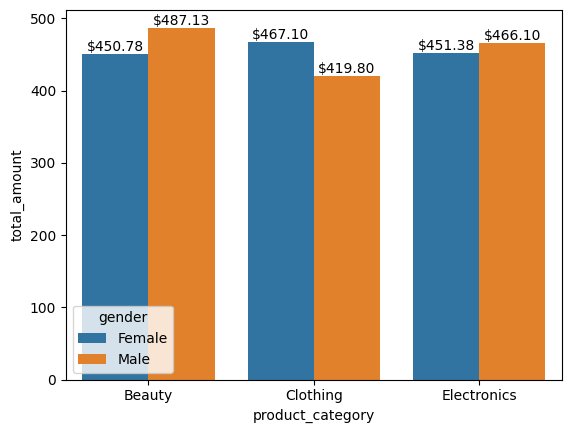

In [49]:
#barplot of average total amount spent based on product category and gender
ax = sns.barplot(df, x='product_category', y='total_amount', hue='gender', errorbar=None)

#add labels to bars
for containers in ax.containers:
    ax.bar_label(containers, fontsize=10, fmt='$%.2f')

# Time Series Analysis

## Monthly Stats

<Axes: xlabel='date'>

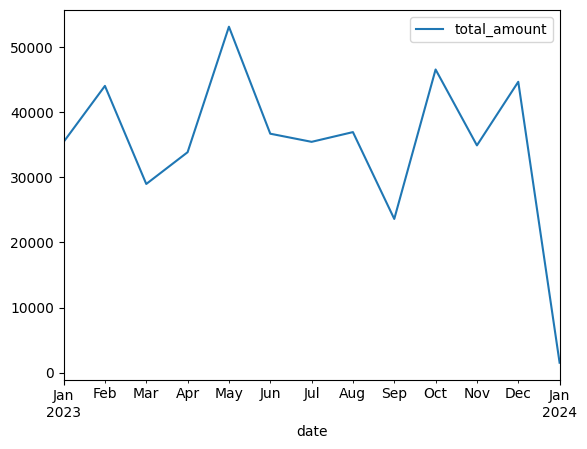

In [50]:
#gross money made per month
wdf = df.copy()
monthly_gross = wdf[['date', 'total_amount']].resample('ME', on='date').sum()
monthly_gross.plot()

<Axes: xlabel='date'>

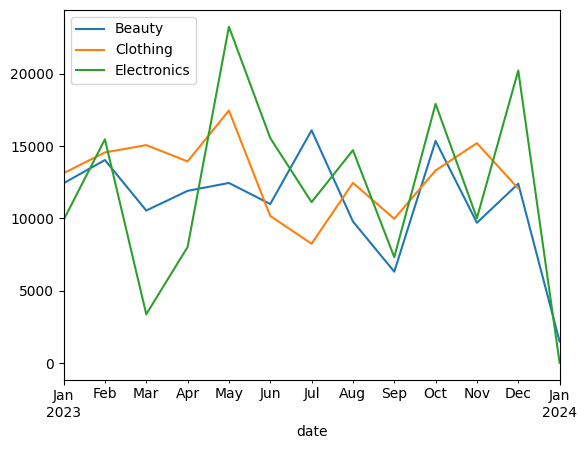

In [51]:
#gross sales per product category per month
df_indexed_by_date_product_category = df.set_index(['date', 'product_category'])
df_indexed_by_date_product_category['total_amount'].groupby([pd.Grouper(level='date', freq='ME'), pd.Grouper(level='product_category')], observed=True).sum().unstack().plot(kind='line')

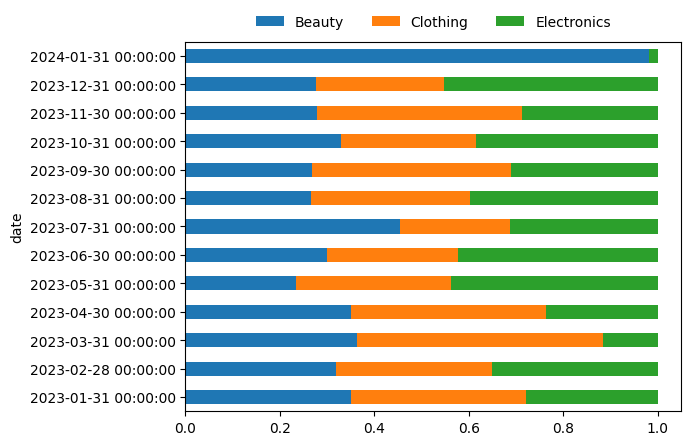

In [52]:
#100% stacked bar chart of gross sales per product category overlaid gross sales per month
data = df_indexed_by_date_product_category['total_amount'].groupby([pd.Grouper(level='date', freq='ME'), pd.Grouper(level='product_category')], observed=True).sum().unstack()
data.div(data.sum(axis=1), axis=0).plot.barh(stacked=True)
plt.legend(
    bbox_to_anchor=(0.5, 1.02),
    loc="lower center",
    borderaxespad=0,
    frameon=False,
    ncol=3,
)

## Quarterly Stats

<Axes: xlabel='date'>

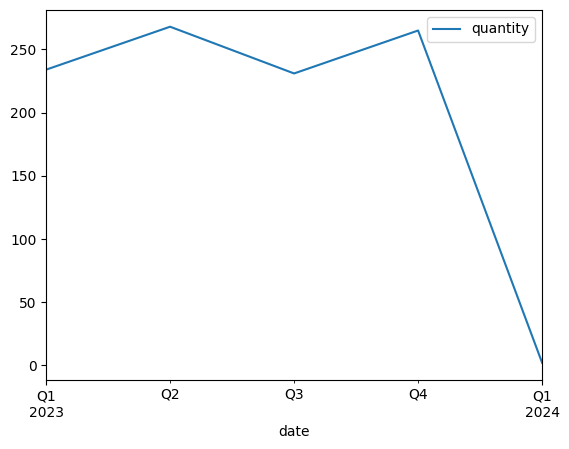

In [53]:
#total sales made per quarter
quarter_sales = wdf[['date', 'quantity']].resample('QE', on='date').count()
quarter_sales.plot()

<Axes: xlabel='date'>

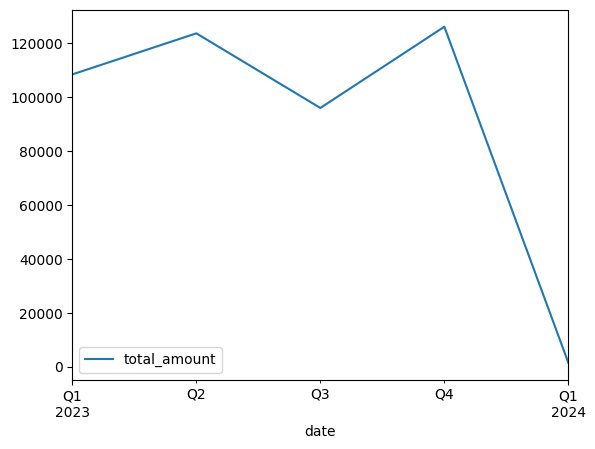

In [54]:
#gross money made per quarter
quarter_gross = wdf[['date', 'total_amount']].resample('QE', on='date').sum()
quarter_gross.plot()

<Axes: xlabel='date'>

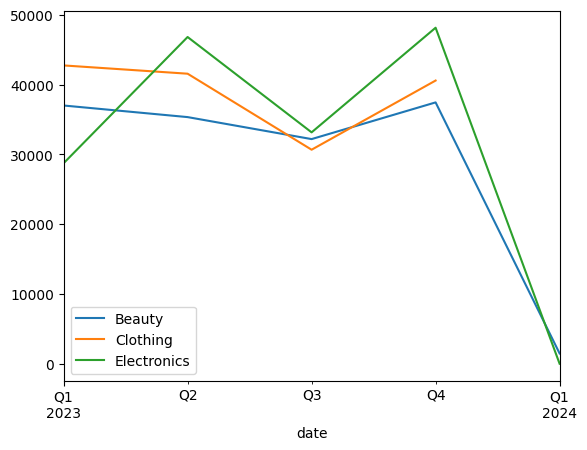

In [55]:
#gross sales per product category per quarter
df_indexed_by_date_product_category = df.set_index(['date', 'product_category'])
df_indexed_by_date_product_category['total_amount'].groupby([pd.Grouper(level='date', freq='QE'), pd.Grouper(level='product_category')], observed=True).sum().unstack().plot(kind='line')